In [71]:
%pip show openpyxl
%pip show xlrd

Name: openpyxl
Version: 3.1.5
Summary: A Python library to read/write Excel 2010 xlsx/xlsm files
Home-page: https://openpyxl.readthedocs.io
Author: See AUTHORS
Author-email: charlie.clark@clark-consulting.eu
License: MIT
Location: /opt/anaconda3/envs/gds24/lib/python3.10/site-packages
Requires: et-xmlfile
Required-by: 
Note: you may need to restart the kernel to use updated packages.
Name: xlrd
Version: 2.0.1
Summary: Library for developers to extract data from Microsoft Excel (tm) .xls spreadsheet files
Home-page: http://www.python-excel.org/
Author: Chris Withers
Author-email: chris@withers.org
License: BSD
Location: /opt/anaconda3/envs/gds24/lib/python3.10/site-packages
Requires: 
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [72]:
%conda install -c conda-forge openpyxl
%pip install xlrd==2.0.1

Retrieving notices: done
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done

## Package Plan ##

  environment location: /opt/anaconda3/envs/gds24

  added / updated specs:
    - openpyxl


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2025.1.31  |       hf0a4a13_0         155 KB  conda-forge
    ------------------------------------------------------------
                                           Total:         155 KB

The following packages will be UPDATED:

  ca-certificates                     2024.12.14-hf0a4a13_0 --> 2025.1.31-hf0a4a13_0 



                                                                                
Preparing transaction: done
Verifying transaction: done
Executing transaction: done

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated package

# Importing the libraries

In [73]:
# Suppress warnings
import warnings

# Data manipulation and analysis
import os  # For file path operations
import pandas as pd  # Data handling and manipulation
import numpy as np  # Numerical operations

# Visualization
import matplotlib.pyplot as plt  # Plotting
import seaborn as sns  # Advanced data visualization

# Spatial data handling and analysis
import geopandas as gpd  # For geospatial data
from pysal.lib import weights  # For spatial weights and lag calculations
import osmnx as ox  # For OpenStreetMap geospatial data

# Interactive widgets for notebooks
import ipywidgets as widgets  # Widgets for interaction
from ipywidgets import interact  # Easy interaction with functions in notebooks

# Statistical analysis
from scipy import stats  # Statistical tests and distributions
import statsmodels.api as sm  # Statistical models and tests
from statsmodels.stats.outliers_influence import variance_inflation_factor  # Multicollinearity diagnostics

# Machine learning
from sklearn.preprocessing import StandardScaler  # Feature scaling
from sklearn.decomposition import PCA  # Principal Component Analysis
from sklearn.linear_model import LinearRegression  # Linear regression model
from sklearn.model_selection import train_test_split  # Train-test split
from sklearn.metrics import mean_squared_error, r2_score  # Regression evaluation metrics


# Loading of the data

The cell below loads the shapefiles for further analysis

In [74]:
# Define file_path
file_path = os.path.join(os.path.dirname(os.getcwd()), 'data')

#https://www.naturalearthdata.com/downloads/110m-cultural-vectors/110m-admin-0-countries/ 
# Correct path to the shapefile directory
path_to_shapefile = os.path.join(file_path, 'ne_110m_admin_0_countries.shp')

# Load the shapefile
world = gpd.read_file(path_to_shapefile)

# Filter out the countries in Europe and keep only the geometry column and Turkey
europe = world[world['CONTINENT'] == 'Europe']
additional_countries = world[world['NAME'].isin({'Turkey', 'Cyprus', 'Georgia', 'Liechtenstein', 'Malta'})]
europe = pd.concat([europe, additional_countries])
europe = europe[['NAME', 'geometry']]

# Ensure the CRS is explicitly set for europe
if europe.crs is None:
    europe.set_crs("EPSG:4326", inplace=True)  # Assuming WGS84 CRS

# Load the Liechtenstein and Malta shapefiles
#https://www.eea.europa.eu/data-and-maps/data/eea-reference-grids-2/gis-files/malta-shapefile
path_to_liechtenstein = os.path.join(file_path, 'li_1km.shp')
#https://www.eea.europa.eu/data-and-maps/data/eea-reference-grids-2/gis-files/liechtenstein-shapefile
path_to_malta = os.path.join(file_path, 'mt_1km.shp')

liechtenstein = gpd.read_file(path_to_liechtenstein)
malta = gpd.read_file(path_to_malta)

# Ensure the CRS is aligned
liechtenstein = liechtenstein.to_crs(europe.crs)
malta = malta.to_crs(europe.crs)

# Dissolve all polygons into one
malta = malta.dissolve()
liechtenstein = liechtenstein.dissolve()

# Ensure the CRS is explicitly set for malta and liechtenstein
if malta.crs is None:
    malta.set_crs(europe.crs, inplace=True)

if liechtenstein.crs is None:
    liechtenstein.set_crs(europe.crs, inplace=True)

# Add the Liechtenstein and Malta geometries to the Europe GeoDataFrame by country name and geometry
liechtenstein_df = gpd.GeoDataFrame([{'NAME': 'Liechtenstein', 'geometry': liechtenstein.geometry.values[0]}], crs=europe.crs)
malta_df = gpd.GeoDataFrame([{'NAME': 'Malta', 'geometry': malta.geometry.values[0]}], crs=europe.crs)

europe = pd.concat([europe, liechtenstein_df, malta_df], ignore_index=True)

#Display the resulting dataframe
europe.head()


,NAME,geometry
0,Russia,"MULTIPOLYGON (((178.7253 71.0988, 180 71.51571..."
1,Norway,"MULTIPOLYGON (((15.14282 79.67431, 15.52255 80..."
2,France,"MULTIPOLYGON (((-51.6578 4.15623, -52.24934 3...."
3,Sweden,"POLYGON ((11.02737 58.85615, 11.46827 59.43239..."
4,Belarus,"POLYGON ((28.17671 56.16913, 29.22951 55.91834..."


This piece of code loads the energy potential file

In [75]:
# Define the file path
file_path = os.path.join(os.path.dirname(os.getcwd()), 'data')

# Correct path to the shapefile directory
#https://data.jrc.ec.europa.eu/collection/id-00138
path_to_file = os.path.join(file_path, 'ENSPRESO_SOLAR_PV_CSP.XLSX')

sheet_name = "MS 170 W per m2 and 3%"

# Load the GDP data from the specified file
energy_potential = pd.read_excel(path_to_file, sheet_name=sheet_name, skiprows=26, engine='openpyxl')

# # Drop the first row
energy_potential = energy_potential.drop(columns=['Unnamed: 0'])

# Transpose the DataFrame
energy_potential = energy_potential.transpose()

# Make the first row the column names
energy_potential.columns = energy_potential.iloc[0]

energy_potential = energy_potential.iloc[3:]

energy_potential.head()


Surface,TOTAL,residential areas roof-top 45 degree south,residential areas roof-top 45 degree east,residential areas roof-top 45 degree west,residential areas roof-top latitude tilt,residential areas facade south,residential areas facade east,residential areas facade west,industrial areas roof-top 45 degree south,industrial areas roof-top 45 degree east,industrial areas roof-top 45 degree west,industrial areas roof-top latitude tilt,industrial areas facade south,industrial areas facade east,industrial areas facade west,natural areas agriculture high irradiation,natural areas agriculture low irradiation,natural areas non-agriculture high irradiation,natural areas non-agriculture low irradiation
Austria,143.932098,1.512456,1.008304,1.008304,1.253759,1.818954,1.818954,1.818954,0.628048,0.418698,0.418698,4.884815,1.10246,1.10246,1.10246,0.0,123.32282,0.0,0.711953
Belgium,94.401343,1.819874,1.213249,1.213249,1.776383,2.235767,2.235767,2.235767,0.777705,0.51847,0.51847,6.04882,1.344364,1.344364,1.344364,0.0,61.35522,0.0,8.419509
Bulgaria,349.636622,1.672925,1.115283,1.115283,1.379248,1.909409,1.909409,1.909409,0.675221,0.450147,0.450147,5.251715,1.123019,1.123019,1.123019,0.0,313.654165,0.0,14.775202
Croatia,114.546134,0.871168,0.580779,0.580779,0.675426,1.054811,1.054811,1.054811,0.403753,0.269169,0.269169,3.140301,0.647046,0.647046,0.647046,0.038294,88.854814,0.026317,13.730596
Cyprus,37.703943,0.27455,0.183033,0.183033,0.238267,0.307886,0.307886,0.307886,0.100076,0.066717,0.066717,0.778365,0.177453,0.177453,0.177453,3.848713,6.850709,8.509981,15.147766


This code loads the gdp file

In [76]:
# Define the file path
file_path = os.path.join(os.path.dirname(os.getcwd()), 'data')

# Correct path to the directory
#https://data.worldbank.org/indicator/NY.GDP.MKTP.CD?end=2023&locations=EU&start=2014
path_to_file = os.path.join(file_path, 'API_NY.GDP.MKTP.CD_DS2_en_excel_v2_124.xls')

# Load the GDP data from the specified file
try:
    gdp_countries = pd.read_excel(path_to_file, skiprows=3, engine='xlrd')
except ImportError:
    print("Ensure 'xlrd' is updated to version 2.0.1 or later.")
    raise

# Filter columns
base_columns = ['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code']
year_columns = [str(year) for year in range(2014, 2024)]  # Columns for 2014 to 2023

gdp_countries_filtered = gdp_countries[base_columns + year_columns]

gdp_countries_filtered.set_index('Country Name', inplace=True)

# Preview the filtered DataFrame
gdp_countries_filtered.head()


,Country Code,Indicator Name,Indicator Code,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
Country Name,,,,,,,,,,,,,
Aruba,ABW,GDP (current US$),NY.GDP.MKTP.CD,2.790850e+09,2.962907e+09,2.983635e+09,3.092429e+09,3.276184e+09,3.395799e+09,2.481857e+09,2.929447e+09,3.279344e+09,3.648573e+09
Africa Eastern and Southern,AFE,GDP (current US$),NY.GDP.MKTP.CD,9.787083e+11,8.982778e+11,8.289428e+11,9.729989e+11,1.012306e+12,1.009721e+12,9.333918e+11,1.085745e+12,1.191423e+12,1.245472e+12
Afghanistan,AFG,GDP (current US$),NY.GDP.MKTP.CD,2.049713e+10,1.913422e+10,1.811657e+10,1.875346e+10,1.805322e+10,1.879944e+10,1.995593e+10,1.426000e+10,1.449724e+10,1.723305e+10
Africa Western and Central,AFW,GDP (current US$),NY.GDP.MKTP.CD,8.974157e+11,7.717669e+11,6.943610e+11,6.878492e+11,7.704950e+11,8.264838e+11,7.898017e+11,8.493124e+11,8.839739e+11,7.991060e+11
Angola,AGO,GDP (current US$),NY.GDP.MKTP.CD,1.359668e+11,9.049642e+10,5.276162e+10,7.369015e+10,7.945069e+10,7.089796e+10,4.850156e+10,6.650513e+10,1.043997e+11,8.482465e+10


This code loads the solar pv prices

In [77]:
# https://ourworldindata.org/grapher/solar-pv-prices?time=earliest..2023#explore-the-data

# Solar PV prices in USD per watt, adjusted for inflation in the world
file_path = os.path.join(os.path.dirname(os.getcwd()), 'data', 'solar-pv-prices.csv')
solar_pv_prices = pd.read_csv(file_path)
solar_pv_prices = solar_pv_prices.set_index('Year')
solar_pv_prices = solar_pv_prices.loc[2013:2023]['Solar photovoltaic module price']

solar_pv_prices.head()

Year
2013    0.813958
2014    0.750229
2015    0.697721
2016    0.644780
2017    0.540990
Name: Solar photovoltaic module price, dtype: float64

The code below loads all the eurostat data

In [78]:
def eurostat_cleaning(df):
    # Remove unnamed columns
    cols = [col for col in df.columns if not col.startswith('Unnamed')]
    df = df[cols]
    
    # Rename the first column to 'Country'
    df = df.rename(columns={df.columns[0]: 'Country'})
    
    # Set 'Country' as the index
    df = df.set_index('Country')
    
    # Replace ':' with NaN explicitly on each column to avoid downcasting issues
    for col in df.columns:
        df[col] = df[col].replace(':', np.nan)
    
    # Explicitly convert numeric columns to float
    for col in df.columns:
        try:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        except Exception as e:
            print(f"Could not convert column {col} to numeric: {e}")
    
    # Clean up the index and filter rows
    df.index = df.index.str.replace('*', '', regex=False)
    df = df.loc['Belgium':'Türkiye']
    
    return df

In [79]:
# Suppress specific FutureWarnings
warnings.filterwarnings("ignore", category=FutureWarning, message=".*Downcasting behavior in `replace` is deprecated.*")

# Navigate up one folder and into the 'data' directory
#https://ec.europa.eu/eurostat/databrowser/view/TEN00124__custom_7069865/default/table?lang=en
file_path = os.path.join(os.path.dirname(os.getcwd()), 'data', 'ten00124_spreadsheet.xlsx')
energy_use_eurostat = []
for i in range (1,6):
    energy_use_eurostat.append(eurostat_cleaning(pd.read_excel(file_path, sheet_name=f'Sheet {i}', skiprows=9)))

#https://ec.europa.eu/eurostat/databrowser/view/nrg_ind_pehnf/default/table?lang=en
file_path = os.path.join(os.path.dirname(os.getcwd()), 'data', 'nrg_ind_pehnf__custom_15047016_spreadsheet.xlsx')
photovoltaic_eurostat = []
for i in range (1,16):
    photovoltaic_eurostat.append(eurostat_cleaning(pd.read_excel(file_path, sheet_name=f'Sheet {i}', skiprows=11)))

#https://ec.europa.eu/eurostat/databrowser/view/ten00117/default/table?lang=en
file_path = os.path.join(os.path.dirname(os.getcwd()), 'data', 'ten00117_page_spreadsheet.xlsx')
energy_price_eurostat = []
for i in range(1, 2):
    energy_price_eurostat.append(eurostat_cleaning(pd.read_excel(file_path, sheet_name=f'Sheet {i}', skiprows=10)))
energy_price_eurostat[0]['2013'] = energy_price_eurostat[0]['2013'].to_numpy().astype(float)

file_path = os.path.join(os.path.dirname(os.getcwd()), 'data', 'population_demographics_eurostat.xlsx')
population_demographics_eurostat = []
for i in range(1, 7):
    population_demographics_eurostat.append(eurostat_cleaning(pd.read_excel(file_path, sheet_name=f'Sheet {i}', skiprows=10)))

file_path = os.path.join(os.path.dirname(os.getcwd()), 'data', 'population_eurostat.xlsx')
population_eurostat = []
for i in range(1, 2):
    population_eurostat.append(eurostat_cleaning(pd.read_excel(file_path, sheet_name=f'Sheet {i}', skiprows=7)))
population_eurostat[0]['2013'] = population_eurostat[0]['2013'].to_numpy().astype(float)

photovoltaic_eurostat[0].head()

/opt/anaconda3/envs/gds24/lib/python3.10/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/envs/gds24/lib/python3.10/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/envs/gds24/lib/python3.10/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/envs/gds24/lib/python3.10/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/envs/gds24/lib/python3.10/site-packages/openp

,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
Country,,,,,,,,,,
Belgium,2886.400,3056.500,3095.400,3308.000,3903.536,4252.395,5112.691,5622.700,6878.800,7820.000
Bulgaria,1256.651,1381.661,1387.990,1402.970,1342.788,1417.286,1468.720,1466.598,2093.838,3520.709
Czechia,2122.869,2263.846,2131.455,2199.263,2364.775,2316.154,2294.363,2249.863,2626.272,2892.093
Denmark,595.518,604.262,743.780,751.485,952.973,963.269,1180.532,1308.929,2202.567,3363.278
Germany,36056.000,38726.000,38098.000,39401.000,43459.000,44383.000,49496.000,50472.000,61022.000,63576.000


# First exploratory data analysis
All the necessary datasets have been downloaded and some first cleaning has been done.

Now the datatypes and NaNs etc will be checked before the datasets can be used for further analysis

In [80]:
# Check whether any country has NaN values for all columns in any of the sheets

# Unit of Measure: 1000 tonnes of oil equivalent
sheet_descriptions_energy_use = {
	0: "Final consumption - energy use",
	1: "Final consumption - industry sector - energy use",
	2: "Final consumption - transport sector - energy use",
	3: "Final consumption - other sectors - commercial and public services - energy use",
	4: "Final consumption - other sectors - households - energy use"
}

# Unit of Measure: GWh
sheet_descriptions_photovoltaic = {
	0: "Solar photovoltaic",
	1: "Solar photovoltaic (< 10 kW)",
	2: "Solar photovoltaic (< 10 kW, roof top)",
	3: "Solar photovoltaic (< 10 kW, off grid)",
	4: "Solar photovoltaic (< 20 kW)",
	5: "Solar photovoltaic (< 30 kW)",
	6: "Solar photovoltaic (< 30 kW, roof top)",
	7: "Solar photovoltaic (< 30 kW, off grid)",
	8: "Solar photovoltaic (20 kW - 1000 kW)",
	9: "Solar photovoltaic (30 kW - 1000 kW)",
	10: "Solar photovoltaic (30 kW - 1000 kW, roof top)",
	11: "Solar photovoltaic (30 kW - 1000 kW, Off grid)",
	12: "Solar photovoltaic (1+ MW)",
	13: "Solar photovoltaic (1+ MW, roof top)",
	14: "Solar photovoltaic (1+ MW, off grid)",
	15: "Solar photovoltaic (off grid)"
}

# Unit of Measure: Euro per KWh
sheet_descriptions_energy_price = {
	0: "Energy price"
}

# Unit of Measure: Percentage
sheet_descriptions_population_demographics = {
	0: "Less than primary, primary and lower secondary education (levels 0-2)",
	1: "Upper secondary, post-secondary non-tertiary and tertiary education (levels 3-8)",
	2: "Upper secondary and post-secondary non-tertiary education (levels 3 and 4)",
	3: "Upper secondary and post-secondary non-tertiary education (levels 3 and 4) - general",
	4: "Upper secondary and post-secondary non-tertiary education (levels 3 and 4) - vocational",
	5: "Tertiary education (levels 5-8)"
}

# Unit of Measure: Number of people
sheet_descriptions_population = {
    0: 'Population on 1 January - total'
}

def check_nan_countries(sheet, sheet_descriptions, printy = True):
	nan_set = set()
	for idx, sheet in enumerate(sheet):
		nan_countries = sheet[sheet.isna().all(axis=1)]
		if nan_set == set() and idx == 0:
			nan_set = set(nan_countries.index.tolist())
		if not nan_countries.empty and printy:
			print(f'Sheet {idx+1}, List index {idx}:\t"{sheet_descriptions[idx]}" \nNaN for all columns:')
			print(f'\t{nan_countries.index.tolist()}\n')
			nan_set = nan_set.intersection(set(nan_countries.index.tolist()))
		else:
			if printy:
				print(f'Sheet {idx+1}, List index {idx}: "{sheet_descriptions[idx]}"\nNo NaN for all columns\n')		
	print(f'The following countries missed all values from all sheets: \t {"None" if nan_set == set() else nan_set}\n')

check_nan_countries(energy_use_eurostat, sheet_descriptions_energy_use, False)
check_nan_countries(photovoltaic_eurostat, sheet_descriptions_photovoltaic, False)
check_nan_countries(energy_price_eurostat, sheet_descriptions_energy_price, False)
check_nan_countries(population_demographics_eurostat, sheet_descriptions_population_demographics, False)
check_nan_countries(population_eurostat, sheet_descriptions_population, False)

The following countries missed all values from all sheets: 	 {'Liechtenstein', 'Switzerland'}

The following countries missed all values from all sheets: 	 None

The following countries missed all values from all sheets: 	 {'Switzerland'}

The following countries missed all values from all sheets: 	 None

The following countries missed all values from all sheets: 	 None



In [81]:
# List of datasets from Eurostat
datasets = [energy_use_eurostat, photovoltaic_eurostat, energy_price_eurostat, population_demographics_eurostat, population_eurostat]

# Check if all countries are present in all datasets (by checking the first of every dataset) using set operations
dataset_set = set(datasets[0][0].index.tolist())
dataset_set_full = set()
for dataset in datasets:
	dataset_set = dataset_set.intersection(set(dataset[0].index.tolist()))
	dataset_set_full = dataset_set_full.union(set(dataset[0].index.tolist()))

print(f'{dataset_set_full - dataset_set} are missing in at least one of the datasets\n')

# Check if all names are coherent with the europe shapefile
europe_set = set(europe['NAME'].tolist())
print(f'{dataset_set_full - europe_set} are missing in the europe shapefile')

# Rename turkey to Türkiye and Bosnia and Herz. to Bosnia and Herzegovina
europe = europe.replace('Turkey', 'Türkiye')
europe = europe.replace('Bosnia and Herz.', 'Bosnia and Herzegovina')

europe_set = set(europe['NAME'].tolist())
print(f'{dataset_set_full - europe_set} are missing in the europe shapefile after renaming')

{'Metropolitan France', 'Albania', 'Liechtenstein', 'Switzerland', 'Moldova', 'Georgia'} are missing in at least one of the datasets

{'Metropolitan France', 'Bosnia and Herzegovina', 'Türkiye'} are missing in the europe shapefile
{'Metropolitan France'} are missing in the europe shapefile after renaming


## These parts of the code are setting the dataframes up to be put into seperate years

In [82]:
# List of datasets and their descriptions
list_of_datasets = [energy_use_eurostat, photovoltaic_eurostat, energy_price_eurostat,
            population_demographics_eurostat, population_eurostat]

sheet_descriptions = {
    "energy_use_eurostat": sheet_descriptions_energy_use,
    "photovoltaic_eurostat": sheet_descriptions_photovoltaic,
    "energy_price_eurostat": sheet_descriptions_energy_price,
    "population_demographics_eurostat": sheet_descriptions_population_demographics,
    "population_eurostat": sheet_descriptions_population
}

def single_dataset_prep(df_year, year, sheet_descriptions):
    for dataset_name, datasets in zip(sheet_descriptions.keys(), list_of_datasets):
        for idx, data in enumerate(datasets):
            df = data[year] if year in data else pd.Series([np.nan] * len(data.columns), index=data.columns)
            df = df.to_frame()
            df.columns = [f'{sheet_descriptions[dataset_name][idx]}']
            df_year = pd.concat([df_year, df], axis=1)
    return df_year

def dataset_additional_columns(dataset, year):
    # Solar PV prices

    # If the year is not in the solar_pv_prices, we will use np.nan
    if int(year) not in solar_pv_prices.index:
        solar_pv = pd.Series([np.nan] * len(dataset), index=dataset.index, name='Solar photovoltaic module price')
    else:
        solar_pv = solar_pv_prices.loc[int(year)]
        solar_pv = pd.Series([solar_pv] * len(dataset), index=dataset.index, name='Solar photovoltaic module price')
    
    dataset = pd.merge(dataset, solar_pv, left_index=True, right_index=True, how='inner')

    # Energy potential
    dataset = pd.merge(dataset, energy_potential, left_index=True, right_index=True)

    # GDP
    if year not in gdp_countries_filtered.columns:
        gdps = pd.Series([np.nan] * len(dataset), index=dataset.index, name='GDP')
        dataset['GDP'] = gdps
    else:
        dataset = pd.merge(dataset, gdp_countries_filtered[year], left_index=True, right_index=True)
        dataset.rename(columns={year: 'GDP'}, inplace=True)
    return dataset

This code creates a dataframe per year for per country with energy consumption and GDP

In [83]:
df_2013 = pd.DataFrame()
df_2014 = pd.DataFrame()
df_2015 = pd.DataFrame()
df_2016 = pd.DataFrame()
df_2017 = pd.DataFrame()
df_2018 = pd.DataFrame()
df_2019 = pd.DataFrame()
df_2020 = pd.DataFrame()
df_2021 = pd.DataFrame()
df_2022 = pd.DataFrame()
df_2023 = pd.DataFrame()
df_2024 = pd.DataFrame()

df_2013 = gpd.GeoDataFrame(single_dataset_prep(df_2013, '2013', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2013 = dataset_additional_columns(df_2013, '2013')
df_2014 = gpd.GeoDataFrame(single_dataset_prep(df_2014, '2014', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2014 = dataset_additional_columns(df_2014, '2014')
df_2015 = gpd.GeoDataFrame(single_dataset_prep(df_2015, '2015', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2015 = dataset_additional_columns(df_2015, '2015')
df_2016 = gpd.GeoDataFrame(single_dataset_prep(df_2016, '2016', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2016 = dataset_additional_columns(df_2016, '2016')
df_2017 = gpd.GeoDataFrame(single_dataset_prep(df_2017, '2017', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2017 = dataset_additional_columns(df_2017, '2017')
df_2018 = gpd.GeoDataFrame(single_dataset_prep(df_2018, '2018', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2018 = dataset_additional_columns(df_2018, '2018')
df_2019 = gpd.GeoDataFrame(single_dataset_prep(df_2019, '2019', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2019 = dataset_additional_columns(df_2019, '2019')
df_2020 = gpd.GeoDataFrame(single_dataset_prep(df_2020, '2020', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2020 = dataset_additional_columns(df_2020, '2020')
df_2021 = gpd.GeoDataFrame(single_dataset_prep(df_2021, '2021', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2021 = dataset_additional_columns(df_2021, '2021')
df_2022 = gpd.GeoDataFrame(single_dataset_prep(df_2022, '2022', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2022 = dataset_additional_columns(df_2022, '2022')
df_2023 = gpd.GeoDataFrame(single_dataset_prep(df_2023, '2023', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2023 = dataset_additional_columns(df_2023, '2023')
df_2024 = gpd.GeoDataFrame(single_dataset_prep(df_2024, '2024', sheet_descriptions).merge(europe, left_index=True, right_on='NAME').set_index('NAME'))
df_2024 = dataset_additional_columns(df_2024, '2024')

all_years = [df_2013, df_2014, df_2015, df_2016, df_2017, df_2018, df_2019, df_2020, df_2021, df_2022, df_2023, df_2024]

# Add the Sun Ratio column to each year 
for i in all_years:
    i["Sun Ratio"] = i["Solar photovoltaic"] / i["TOTAL"]

df_2014["Sun Ratio"].head()

Belgium     30.575836
Bulgaria     3.594163
Denmark        4.3855
Germany     40.232646
Estonia           0.0
Name: Sun Ratio, dtype: object

In [84]:
import matplotlib.cm as cm
import matplotlib.colors as colors


y_range, x_range = [[30, 75],[-25, 45]]

def plot_data(year, variable):
    df = globals()[f'df_{year}']
    if variable in df.columns:
        fig, ax = plt.subplots(figsize=(20, 7))  # Create figure and axis
        ax.clear()  # Clear the previous plot instead of creating a new figure

        # Define colormap normalization
        vmin, vmax = df[variable].min(), df[variable].max()
        norm = colors.Normalize(vmin=vmin, vmax=vmax)
        sm = cm.ScalarMappable(cmap='viridis', norm=norm)
        sm.set_array([])

        df.plot(column=variable, cmap='viridis', linewidth=0.8, ax=ax, edgecolor='black', legend=False)

        # Add colorbar
        cbar = fig.colorbar(sm, ax=ax, aspect=20)
        cbar.set_label(variable, fontsize=12)

        ax.set_title(f'{variable} in {year}')
        ax.set_xlim(x_range)
        ax.set_ylim(y_range)
        
        plt.show()
    else:
        print(f'{variable} not found in the dataset for {year}')

years = range(2014, 2024)
variables = ["Solar photovoltaic", "Final consumption - energy use",
                   "Population on 1 January - total", "Solar photovoltaic module price",
                   "TOTAL", "GDP", "Tertiary education (levels 5-8)", "Sun Ratio"
                  ]

year_slider = widgets.IntSlider(min=min(years), max=max(years), step=1, value=min(years))
variable_dropdown = widgets.Dropdown(options=variables, description='Variable:')

interact(plot_data, year=year_slider, variable=variable_dropdown)

interactive(children=(IntSlider(value=2014, description='year', max=2023, min=2014), Dropdown(description='Var…

<function __main__.plot_data(year, variable)>

In [85]:
# List of countries and variables
countries = df_2013.index.tolist()
variables = df_2013.columns.tolist()
variables.remove('geometry')

# Dropdown widgets for country and variable selection
country_dropdown = widgets.Dropdown(options=countries, description='Country:')
variable_dropdown = widgets.Dropdown(options=variables, description='Variable:')

def plot_variable_over_years(country, variable):
    years = range(2013, 2025)
    values = []
    for year in years:
        df = globals()[f'df_{year}']
        if variable in df.columns and country in df.index:
            values.append(df.loc[country, variable])
        else:
            values.append(None)
    
    plt.figure(figsize=(10, 5))
    plt.plot(years, values, marker='o', color='r')
    plt.title(f'{variable} in {country} (2013-2024)')
    plt.xlabel('Year')
    plt.ylabel(variable)
    plt.grid(True)
    plt.show()

interact(plot_variable_over_years, country=country_dropdown, variable=variable_dropdown)

interactive(children=(Dropdown(description='Country:', options=('Belgium', 'Bulgaria', 'Denmark', 'Germany', '…

<function __main__.plot_variable_over_years(country, variable)>

## Further with checking missing data

In [86]:
# Missing data per year
dct = {}
counter = 2013
for year in all_years:
    dct[counter] =year.isna().sum().sum()
    counter += 1

print('The number of missing values per year is:')
display(dct)


The number of missing values per year is:


{2013: 575,
 2014: 195,
 2015: 186,
 2016: 177,
 2017: 168,
 2018: 150,
 2019: 150,
 2020: 155,
 2021: 84,
 2022: 86,
 2023: 127,
 2024: 727}

In [87]:
# Countries with most missing data in total
dct = {}
for year in all_years:
    countries = year.isna().sum(axis=1)
    for country in countries.index:
        if country not in dct:
            dct[country] = countries[country]
        else:
            dct[country] += countries[country]

print(f'The countries with the most missing data in total sorted are:\n {sorted(dct.items(),key= lambda x: x[1], reverse=True)}')

The countries with the most missing data in total sorted are:
 [('United Kingdom', 246), ('Romania', 165), ('Croatia', 158), ('Germany', 149), ('Italy', 149), ('Malta', 149), ('Finland', 134), ('Lithuania', 125), ('Latvia', 122), ('Estonia', 104), ('Greece', 100), ('Netherlands', 95), ('Belgium', 86), ('Bulgaria', 86), ('Denmark', 86), ('Ireland', 86), ('Spain', 86), ('France', 86), ('Cyprus', 86), ('Austria', 86), ('Poland', 86), ('Portugal', 86), ('Slovenia', 86), ('Sweden', 86), ('Slovakia', 52)]


In [88]:
all_years = all_years[1:-1]
# Countries with most missing data in total
dct = {}
for year in all_years:
    countries = year.isna().sum(axis=1)
    for country in countries.index:
        if country not in dct:
            dct[country] = countries[country]
        else:
            dct[country] += countries[country]

print(f'The countries with the most missing data in total sorted are:\n {sorted(dct.items(),key= lambda x: x[1], reverse=True)}')

The countries with the most missing data in total sorted are:
 [('United Kingdom', 192), ('Romania', 113), ('Croatia', 106), ('Germany', 97), ('Italy', 97), ('Malta', 97), ('Finland', 82), ('Lithuania', 73), ('Latvia', 70), ('Estonia', 52), ('Greece', 48), ('Netherlands', 43), ('Belgium', 34), ('Bulgaria', 34), ('Denmark', 34), ('Ireland', 34), ('Spain', 34), ('France', 34), ('Cyprus', 34), ('Austria', 34), ('Poland', 34), ('Portugal', 34), ('Slovenia', 34), ('Sweden', 34)]


In [89]:
# Columns with most missing data in total
dct = {}
total_rows = sum([len(year) for year in all_years])
for year in all_years:
    columns = year.isna().sum()
    for column in columns.index:
        if column not in dct:
            dct[column] = columns[column]
        else:
            dct[column] += columns[column]

# Convert counts to percentages
for column in dct:
    dct[column] = (dct[column] / total_rows) * 100

print(f'The columns with the most missing data in total sorted are:\n {sorted(dct.items(),key= lambda x: x[1], reverse=True)}')

The columns with the most missing data in total sorted are:
 [('Upper secondary and post-secondary non-tertiary education (levels 3 and 4) - general', 71.25), ('Upper secondary and post-secondary non-tertiary education (levels 3 and 4) - vocational', 71.25), ('Solar photovoltaic (< 20 kW)', 67.08333333333333), ('Solar photovoltaic (20 kW - 1000 kW)', 67.08333333333333), ('Solar photovoltaic (< 30 kW)', 36.666666666666664), ('Solar photovoltaic (30 kW - 1000 kW)', 36.666666666666664), ('Solar photovoltaic (< 10 kW)', 26.666666666666668), ('Solar photovoltaic (< 10 kW, roof top)', 26.666666666666668), ('Solar photovoltaic (< 10 kW, off grid)', 26.666666666666668), ('Solar photovoltaic (< 30 kW, roof top)', 26.666666666666668), ('Solar photovoltaic (< 30 kW, off grid)', 26.666666666666668), ('Solar photovoltaic (30 kW - 1000 kW, roof top)', 26.666666666666668), ('Solar photovoltaic (30 kW - 1000 kW, Off grid)', 26.666666666666668), ('Solar photovoltaic (1+ MW, roof top)', 26.6666666666666

### If more than 25% of the data is missing, we will drop the column

In [90]:
# If more than 25% of the data is missing, we will drop the column
columns_to_drop = [column for column in dct if dct[column] > 25]
print(f'The columns with more than 25% missing data are: {columns_to_drop}')

# Drop the columns with more than 25% missing data
for year in all_years:
    year.drop(columns=columns_to_drop, inplace=True)


The columns with more than 25% missing data are: ['Solar photovoltaic (< 10 kW)', 'Solar photovoltaic (< 10 kW, roof top)', 'Solar photovoltaic (< 10 kW, off grid)', 'Solar photovoltaic (< 20 kW)', 'Solar photovoltaic (< 30 kW)', 'Solar photovoltaic (< 30 kW, roof top)', 'Solar photovoltaic (< 30 kW, off grid)', 'Solar photovoltaic (20 kW - 1000 kW)', 'Solar photovoltaic (30 kW - 1000 kW)', 'Solar photovoltaic (30 kW - 1000 kW, roof top)', 'Solar photovoltaic (30 kW - 1000 kW, Off grid)', 'Solar photovoltaic (1+ MW, roof top)', 'Solar photovoltaic (1+ MW, off grid)', 'Upper secondary and post-secondary non-tertiary education (levels 3 and 4) - general', 'Upper secondary and post-secondary non-tertiary education (levels 3 and 4) - vocational']


In [91]:
dct = {}
for year in all_years:
    countries = year.isna().sum(axis=1)
    for country in countries.index:
        if country not in dct:
            dct[country] = countries[country]
        else:
            dct[country] += countries[country]

print(f'The countries with the most missing data in total sorted are:\n {sorted(dct.items(),key= lambda x: x[1], reverse=True)}')

The countries with the most missing data in total sorted are:
 [('United Kingdom', 54), ('Greece', 3), ('Romania', 3), ('Lithuania', 1), ('Finland', 1), ('Belgium', 0), ('Bulgaria', 0), ('Denmark', 0), ('Germany', 0), ('Estonia', 0), ('Ireland', 0), ('Spain', 0), ('France', 0), ('Croatia', 0), ('Italy', 0), ('Cyprus', 0), ('Latvia', 0), ('Malta', 0), ('Netherlands', 0), ('Austria', 0), ('Poland', 0), ('Portugal', 0), ('Slovenia', 0), ('Sweden', 0)]


In [92]:
dct = {}
total_cells = sum([year.shape[1] for year in all_years])
for year in all_years:
    countries = year.isna().sum(axis=1)
    for country in countries.index:
        if country not in dct:
            dct[country] = countries[country]
        else:
            dct[country] += countries[country]

# Convert counts to percentages
for country in dct:
    dct[country] = (dct[country] / total_cells) * 100

print(f'The countries with the most missing data in total sorted are:\n {sorted(dct.items(), key=lambda x: x[1], reverse=True)}')

The countries with the most missing data in total sorted are:
 [('United Kingdom', 15.0), ('Greece', 0.8333333333333334), ('Romania', 0.8333333333333334), ('Lithuania', 0.2777777777777778), ('Finland', 0.2777777777777778), ('Belgium', 0.0), ('Bulgaria', 0.0), ('Denmark', 0.0), ('Germany', 0.0), ('Estonia', 0.0), ('Ireland', 0.0), ('Spain', 0.0), ('France', 0.0), ('Croatia', 0.0), ('Italy', 0.0), ('Cyprus', 0.0), ('Latvia', 0.0), ('Malta', 0.0), ('Netherlands', 0.0), ('Austria', 0.0), ('Poland', 0.0), ('Portugal', 0.0), ('Slovenia', 0.0), ('Sweden', 0.0)]


In [93]:
dct = {}
total_cells = sum([year.shape[1] for year in all_years])
for year in all_years:
    countries = year.isna().sum(axis=1)
    for country in countries.index:
        if country not in dct:
            dct[country] = countries[country]
        else:
            dct[country] += countries[country]

print(f'The countries with the most missing data in total sorted are:\n {sorted(dct.items(), key=lambda x: x[1], reverse=True)}')

The countries with the most missing data in total sorted are:
 [('United Kingdom', 54), ('Greece', 3), ('Romania', 3), ('Lithuania', 1), ('Finland', 1), ('Belgium', 0), ('Bulgaria', 0), ('Denmark', 0), ('Germany', 0), ('Estonia', 0), ('Ireland', 0), ('Spain', 0), ('France', 0), ('Croatia', 0), ('Italy', 0), ('Cyprus', 0), ('Latvia', 0), ('Malta', 0), ('Netherlands', 0), ('Austria', 0), ('Poland', 0), ('Portugal', 0), ('Slovenia', 0), ('Sweden', 0)]


### Drop the United Kingdom

In [94]:
# Drop the United Kingdom
for year in all_years:
    year.drop(index='United Kingdom', inplace=True)

In [95]:
# Percentage of missing data
counter = 2014
total_cells = sum([year.shape[0] * year.shape[1] for year in all_years])
for year in all_years:
    # missing += = year.isna().sum()
    print(f"{counter}: {year.isna().sum().sum()}")
    counter += 1

2014: 0
2015: 0
2016: 0
2017: 0
2018: 0
2019: 0
2020: 0
2021: 0
2022: 0
2023: 8


In [96]:
def fill_missing_values(year, previous_year):
    """
    Vervangt NaN-waarden in de 'year'-dataset met waarden uit de 'previous_year'-dataset op dezelfde index.

    Parameters:
        year (pd.DataFrame): Dataset waarin missende waarden worden aangevuld.
        previous_year (pd.DataFrame): Dataset die wordt gebruikt om de missende waarden aan te vullen.

    Returns:
        pd.DataFrame: Dataset met aangevulde waarden.
    """
    # Mask met NaN-waarden in 'year'
    mask = year.isna()
    
    # Vul de missende waarden aan vanuit 'previous_year'
    filled_year = year.copy()
    filled_year[mask] = previous_year[mask]
    
    return filled_year

# Voorbeeld van hoe je de functie gebruikt
all_years[-1] = fill_missing_values(all_years[-1], all_years[-2])


In [97]:
# Percentage of missing data
counter = 2014
total_cells = sum([year.shape[0] * year.shape[1] for year in all_years])
for year in all_years:
    # missing += = year.isna().sum()
    print(f"{counter}: {year.isna().sum().sum()}")
    counter += 1

2014: 0
2015: 0
2016: 0
2017: 0
2018: 0
2019: 0
2020: 0
2021: 0
2022: 0
2023: 0


### Further data prep
The dataset is now cleaned of NaN values and can be put into a long_format since this is better suitable for machine learning purposes

In [98]:
datasets = {
    2014: all_years[0],
    2015: all_years[1],
    2016: all_years[2],
    2017: all_years[3],
    2018: all_years[4],
    2019: all_years[5],
    2020: all_years[6],
    2021: all_years[7],
    2022: all_years[8],
    2023: all_years[9],
}

long_format = pd.concat(
    [df.assign(Year=year).reset_index() for year, df in datasets.items()],
    ignore_index=True
)

# Show result and place the year as second column
long_format = long_format[['index', 'Year'] + long_format.columns[1:-1].tolist()]

In [99]:

# Change all columns to floats except for the 'Country', 'geometry' and 'Year' columns
for column in long_format.columns:
    if column not in ['index', 'Year', 'geometry']:
        long_format[column] = long_format[column].astype(float)

long_format

,index,Year,Final consumption - energy use,Final consumption - industry sector - energy use,Final consumption - transport sector - energy use,Final consumption - other sectors - commercial and public services - energy use,Final consumption - other sectors - households - energy use,Solar photovoltaic,Solar photovoltaic (1+ MW),Energy price,...,industrial areas roof-top latitude tilt,industrial areas facade south,industrial areas facade east,industrial areas facade west,natural areas agriculture high irradiation,natural areas agriculture low irradiation,natural areas non-agriculture high irradiation,natural areas non-agriculture low irradiation,GDP,Sun Ratio
0,Belgium,2014,31550.921,10561.058,8526.843,4227.344,7445.776,2886.400,219.700,0.2097,...,6.048820,1.344364,1.344364,1.344364,0.000000,61.355220,0.000000,8.419509,5.379874e+11,30.575836
1,Bulgaria,2014,8881.501,2617.523,2916.487,992.002,2164.991,1256.651,0.000,0.0832,...,5.251715,1.123019,1.123019,1.123019,0.000000,313.654165,0.000000,14.775202,5.715778e+10,3.594163
2,Denmark,2014,12932.124,2120.599,4031.340,1847.314,4146.276,595.518,0.000,0.3042,...,3.034747,0.665939,0.665939,0.665939,0.000000,119.604928,0.000000,3.832792,3.528326e+11,4.385500
3,Germany,2014,197229.019,55725.644,55445.775,30766.034,53648.149,36056.000,0.000,0.2981,...,43.166994,9.692073,9.692073,9.692073,0.000000,660.157318,0.000000,62.824667,3.965801e+12,40.232646
4,Estonia,2014,2774.349,555.819,741.510,457.642,888.143,0.000,0.000,0.1307,...,0.645284,0.145402,0.145402,0.145402,0.000000,43.499926,0.000000,0.000000,2.705569e+10,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,Portugal,2023,16467.785,4312.786,6173.905,2424.569,3019.665,5160.143,3199.218,0.2071,...,5.672865,1.361536,1.361536,1.361536,73.728627,85.837885,2.164987,5.206934,2.891143e+11,27.062525
226,Romania,2023,23306.216,4958.000,7698.756,2050.182,7552.174,1988.419,1988.419,0.1892,...,12.822640,2.934100,2.934100,2.934100,0.000000,791.711172,0.000000,1.197614,3.507759e+11,2.349246
227,Slovenia,2023,4529.005,1073.341,1834.363,437.184,1040.038,984.359,18.427,0.1917,...,1.361229,0.288613,0.288613,0.288613,0.000000,32.590160,0.000000,0.000000,6.914847e+10,26.065370
228,Finland,2023,22450.838,9292.601,3774.581,2902.969,5531.193,647.000,2.719,0.2557,...,2.701519,0.588034,0.588034,0.588034,0.000000,47.880358,0.000000,0.000000,2.955323e+11,10.961045


# Data visualisation

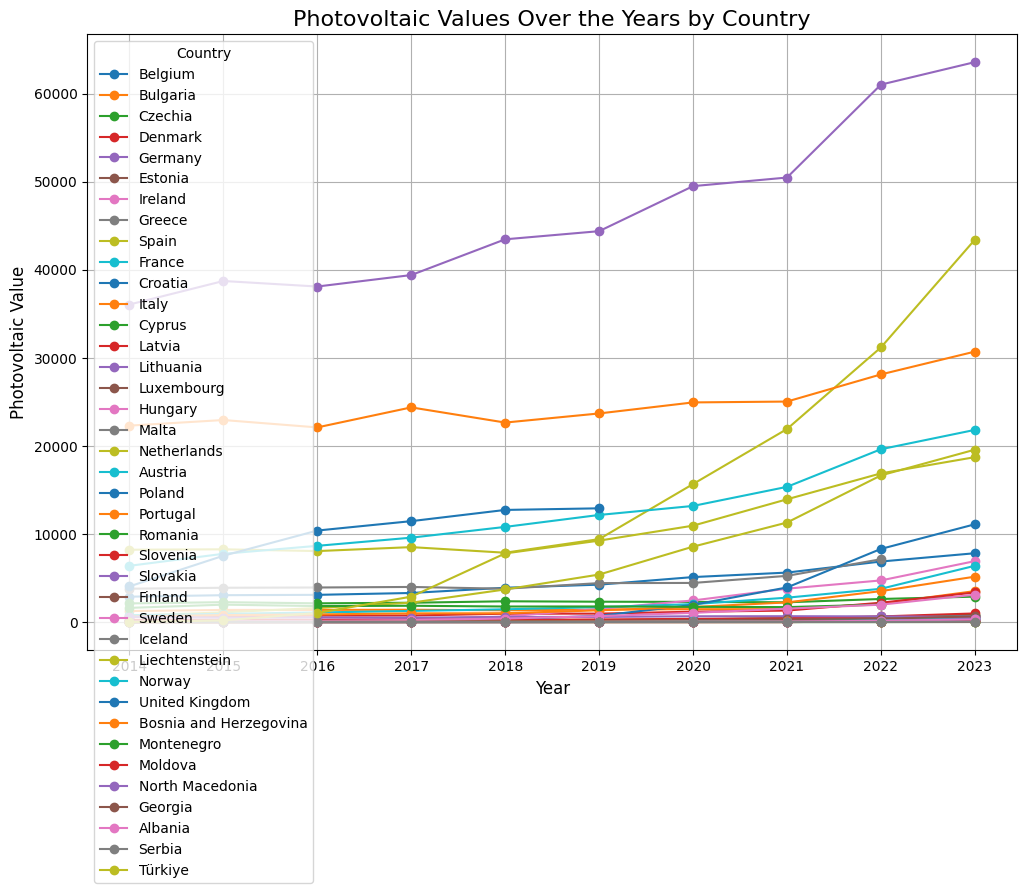

In [100]:
# Transpose the DataFrame to have years as the index and countries as columns
df_transposed = photovoltaic_eurostat[0].T

# Plot each country's photovoltaic over the years
plt.figure(figsize=(12, 8))
for country in df_transposed.columns:
    plt.plot(df_transposed.index, df_transposed[country], marker="o", label=country)

# Add labels, title, and legend
plt.title("Photovoltaic Values Over the Years by Country", fontsize=16)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Photovoltaic Value", fontsize=12)
plt.legend(title="Country", loc="upper left")
plt.grid(True)
plt.show()

In [101]:
columns_to_keep = ["index", "Year", "Solar photovoltaic", "Final consumption - energy use",
                   "Population on 1 January - total","geometry", "Solar photovoltaic module price",
                   "TOTAL", "GDP", "Tertiary education (levels 5-8)"
                  ]

long_format = long_format.loc[:,columns_to_keep]

long_format = long_format.rename(columns={
    "index": "Country",
    "Year": "Year",
    "Solar photovoltaic": "Solar Photovoltaic",
    "Final consumption - energy use": "Energy Consumption",
    "Population on 1 January - total": "Population",
    "geometry": "Geometry",
    "Solar photovoltaic module price": "Solar Photovoltaic Module Price",
    "TOTAL": "Energy Potential",
    "GDP": "GDP",
    "Tertiary education (levels 5-8)": "Tertiary Education"
})

long_format.head()

,Country,Year,Solar Photovoltaic,Energy Consumption,Population,Geometry,Solar Photovoltaic Module Price,Energy Potential,GDP,Tertiary Education
0,Belgium,2014,2886.400,31550.921,11180840.0,"POLYGON ((6.15666 50.80372, 6.04307 50.12805, ...",0.750229,94.401343,5.379874e+11,32.6
1,Bulgaria,2014,1256.651,8881.501,7117453.0,"POLYGON ((22.65715 44.23492, 22.94483 43.82379...",0.750229,349.636622,5.715778e+10,23.6
2,Denmark,2014,595.518,12932.124,5627235.0,"MULTIPOLYGON (((9.92191 54.9831, 9.28205 54.83...",0.750229,135.792490,3.528326e+11,29.4
3,Germany,2014,36056.000,197229.019,80767463.0,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",0.750229,896.187631,3.965801e+12,23.2
4,Estonia,2014,0.000,2774.349,1315819.0,"POLYGON ((27.98113 59.47537, 27.98112 59.47537...",0.750229,46.215746,2.705569e+10,32.6


# Machine learning
**Prep the data for machine learning**

In [102]:
# Columns to exclude from standardization
exclude_columns = ['Year', 'Country','Geometry']

# Columns to standardize
columns_to_standardize = [col for col in long_format.columns if col not in exclude_columns]

# Initialize the StandardScaler
scaler = StandardScaler()

# Standardize the selected columns
long_format[columns_to_standardize] = scaler.fit_transform(long_format[columns_to_standardize])

# Display the standardized DataFrame
display(long_format)

,Country,Year,Solar Photovoltaic,Energy Consumption,Population,Geometry,Solar Photovoltaic Module Price,Energy Potential,GDP,Tertiary Education
0,Belgium,2014,-0.249174,-0.120582,-0.304280,"POLYGON ((6.15666 50.80372, 6.04307 50.12805, ...",1.681104,-0.616354,-0.129641,0.302469
1,Bulgaria,2014,-0.394713,-0.582533,-0.480078,"POLYGON ((22.65715 44.23492, 22.94483 43.82379...",1.681104,-0.115610,-0.621783,-0.941788
2,Denmark,2014,-0.453753,-0.499990,-0.544551,"MULTIPOLYGON (((9.92191 54.9831, 9.28205 54.83...",1.681104,-0.535149,-0.319152,-0.139934
3,Germany,2014,2.712918,3.255560,2.706311,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",1.681104,0.956665,3.378817,-0.997088
4,Estonia,2014,-0.506933,-0.706982,-0.731080,"POLYGON ((27.98113 59.47537, 27.98112 59.47537...",1.681104,-0.710889,-0.652594,0.302469
...,...,...,...,...,...,...,...,...,...,...
225,Portugal,2023,-0.046125,-0.427941,-0.333017,"POLYGON ((-9.03482 41.88057, -8.67195 42.13469...",-1.162604,-0.427476,-0.384370,-0.457910
226,Romania,2023,-0.329365,-0.288590,0.036368,"POLYGON ((28.23355 45.48828, 28.67978 45.30403...",-1.162604,0.859001,-0.321257,-1.978669
227,Slovenia,2023,-0.419029,-0.671226,-0.696419,"POLYGON ((13.80648 46.50931, 14.63247 46.43182...",-1.162604,-0.727468,-0.609511,-0.084633
228,Finland,2023,-0.449155,-0.306020,-0.547288,"POLYGON ((28.59193 69.06478, 28.44594 68.36461...",-1.162604,-0.685754,-0.377801,0.731046


**Identify outliers and delete them from the dataset**

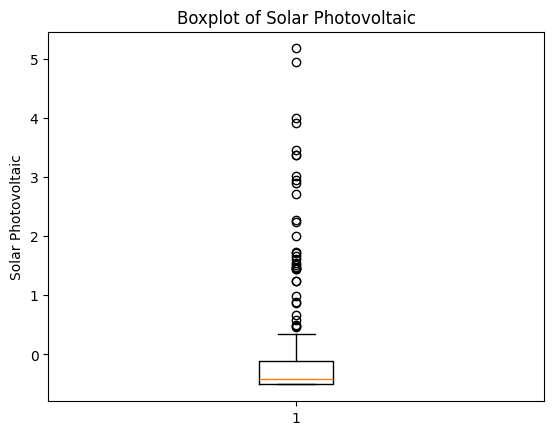

,Country,Year,Solar Photovoltaic,Energy Consumption,Population,Geometry,Solar Photovoltaic Module Price,Energy Potential,GDP,Tertiary Education
210,Germany,2023,5.170492,2.898808,2.861688,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",-1.162604,0.956665,3.951892,-0.195234
187,Germany,2022,4.942417,3.102103,2.813158,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",-0.895763,0.956665,3.581266,-0.347310
164,Germany,2021,4.000287,3.262494,2.809607,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",-1.101951,0.956665,3.770312,-0.333485
141,Germany,2020,3.913129,3.194815,2.810112,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",-0.881035,0.956665,3.352555,-0.444085
118,Germany,2019,3.456531,3.328417,2.803731,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",-0.296350,0.956665,3.370022,-0.609986
95,Germany,2018,3.374016,3.325976,2.793916,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",-0.037739,0.956665,3.467053,-0.720587
214,Spain,2023,3.370623,0.818770,1.292355,"POLYGON ((-7.45373 37.09779, -7.53711 37.4289,...",-1.162604,2.490964,0.977920,0.924597
72,Germany,2017,3.011631,3.403976,2.782204,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",0.342585,0.956665,3.171339,-0.775887
26,Germany,2015,2.951353,3.312664,2.724918,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",1.345209,0.956665,2.823827,-0.914138
49,Germany,2016,2.895271,3.386751,2.767236,"POLYGON ((14.11969 53.75703, 14.35332 53.24817...",1.006544,0.956665,2.940730,-0.831188


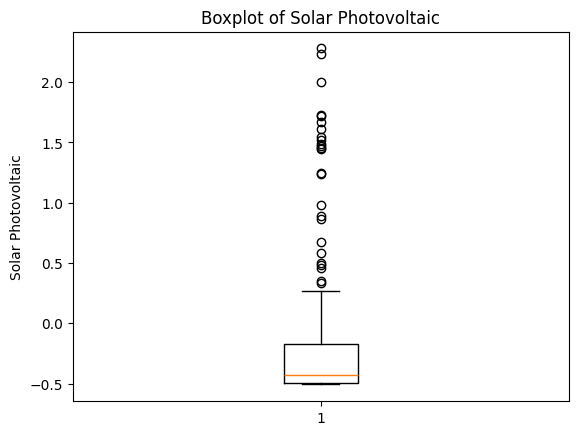

In [103]:
# Sort by 'Solar photovoltaic' for better visualization
long_format = long_format.sort_values(by=['Solar Photovoltaic'], ascending=False)

### BOX PLOT
plt.boxplot(long_format['Solar Photovoltaic'])
plt.title('Boxplot of Solar Photovoltaic')
plt.ylabel('Solar Photovoltaic')
plt.show()

# Calculate Z-scores
z_scores = stats.zscore(long_format['Solar Photovoltaic'])

# Identify outliers
outliers = long_format[(z_scores > 2.5) | (z_scores < -2.5)]
display(outliers)

# Exclude outliers from the dataset
filtered_data = long_format[~((z_scores > 2.5) | (z_scores < -2.5))]

### BOX PLOT
plt.boxplot(filtered_data['Solar Photovoltaic'])
plt.title('Boxplot of Solar Photovoltaic')
plt.ylabel('Solar Photovoltaic')
plt.show()


# The `filtered_data` DataFrame is now ready for further analysis without outliers.


In [104]:
# Perform Multiple Linear Regression

# Define the dependent variable Solar photovoltaic
X = long_format.drop(columns=['Country','Year' ,'Geometry', 'Solar Photovoltaic']) 
y = long_format['Solar Photovoltaic']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a Linear Regression model
model = LinearRegression()

# Fit the model to the training data
model.fit(X_train, y_train)

# Make predictions using the testing set
y_pred = model.predict(X_test)

# The coefficients
print('Coefficients: \n', model.coef_)
# The mean squared error
print('Mean squared error: %.2f' % mean_squared_error(y_test, y_pred))
# The coefficient of determination: 1 is perfect prediction
print('R-squared score: %.2f' % r2_score(y_test, y_pred))

Coefficients: 
 [-1.77075321  1.95137454 -0.09994733 -0.60085375  1.1994936  -0.03772988]
Mean squared error: 0.06
R-squared score: 0.90


                            OLS Regression Results                            
Dep. Variable:     Solar Photovoltaic   R-squared:                       0.866
Model:                            OLS   Adj. R-squared:                  0.862
Method:                 Least Squares   F-statistic:                     190.9
Date:                Thu, 06 Feb 2025   Prob (F-statistic):           1.53e-74
Time:                        13:25:10   Log-Likelihood:                -84.537
No. Observations:                 184   AIC:                             183.1
Df Residuals:                     177   BIC:                             205.6
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

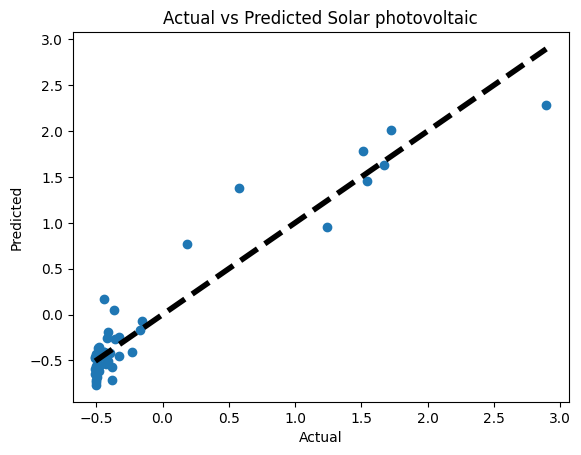

In [105]:
# Now with OLS

# Add a constant to the independent variables
X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

# Create an OLS model
model = sm.OLS(y_train, X_train)

# Fit the model to the training data
results = model.fit()

# Print the summary
print(results.summary())

# Make predictions using the testing set
y_pred = results.predict(X_test)

# The mean squared error
print('Mean squared error: %.2f' % mean_squared_error(y_test, y_pred))
# The coefficient of determination: 1 is perfect prediction
print('R-squared score: %.2f' % r2_score(y_test, y_pred))

# Visualise the results
plt.scatter(y_test, y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted Solar photovoltaic')

# Plot a line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=4)

plt.show()
